# Hotel Booking Cancellation Prediction
### Business Analytics ML Project: Build and Deploy

**Business problem:** Hotels lose revenue when guests cancel bookings, especially at the last minute, because the room often stays empty.
If the hotel can predict **which bookings are likely to be cancelled**, it can act early: ask for a deposit, send reminders, offer incentives, or carefully overbook.

**Goal:** Build a machine learning model that predicts whether a booking will be **Canceled** or **Not Canceled**, and turn it into a Streamlit app that gives a business recommendation.

**Dataset:** Hotel Reservations Dataset (Kaggle): https://www.kaggle.com/datasets/ahsan81/hotel-reservations-classification-dataset
36,275 bookings, 19 columns.

**Project flow:** Business Problem → Dataset → Data Preparation → EDA → ML Model → Evaluation → Prediction → Business Recommendation → Streamlit App → GitHub → Deployment

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Load the data

In [2]:
df = pd.read_csv("Hotel Reservations.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (36275, 19)


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


**What the columns mean**

| Column | Meaning |
|---|---|
| no_of_adults, no_of_children | Number of guests |
| no_of_weekend_nights, no_of_week_nights | Length of stay |
| type_of_meal_plan | Meal package chosen |
| required_car_parking_space | 1 = needs parking |
| room_type_reserved | Room category (coded by the hotel) |
| lead_time | Days between booking date and arrival date |
| arrival_year / month / date | Arrival date |
| market_segment_type | Where the booking came from (Online, Offline, Corporate, ...) |
| repeated_guest | 1 = has stayed before |
| no_of_previous_cancellations | Past cancellations by this guest |
| no_of_previous_bookings_not_canceled | Past completed stays |
| avg_price_per_room | Average price per day (euros) |
| no_of_special_requests | Requests like high floor, view, etc. |
| **booking_status** | **Target: Canceled / Not_Canceled** |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  str    
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  str    
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  str    
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date              

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.030986,0.173281,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.0,1.0


## 3. Data cleaning and preparation

### 3.1 Missing values

In [5]:
df.isnull().sum()

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

There are **no missing values**, so no filling is needed.

### 3.2 Remove the ID column and duplicate rows
`Booking_ID` is just a label and has no predictive value, so we drop it.
After dropping it, many rows are **exact copies** of each other. If identical rows appear in both the training and test sets, the model is tested on rows it has already seen, which makes the score look better than it really is. So we remove duplicates to get an **honest** evaluation.

In [6]:
df = df.drop(columns="Booking_ID")
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Duplicate rows: 10275
Rows after removing duplicates: 26000


### 3.3 Fix impossible or suspicious values
- **Invalid dates:** some rows have 29 February 2018, which does not exist (2018 was not a leap year).
- **Zero-night stays:** a booking with 0 nights is not a real stay.
- **Zero price:** a price of 0 is fine for *Complementary* (free) rooms, but suspicious for paid segments.
- **Extreme outliers:** a very small number of rows have price above 500 or more than 3 children.

In [7]:
before = len(df)
dates = pd.to_datetime(dict(year=df.arrival_year, month=df.arrival_month, day=df.arrival_date), errors="coerce")
print("Invalid dates:", dates.isna().sum())
df = df[dates.notna()]

total_nights = df.no_of_weekend_nights + df.no_of_week_nights
print("Zero-night bookings:", (total_nights == 0).sum())
df = df[total_nights > 0]

bad_price = (df.avg_price_per_room == 0) & (df.market_segment_type != "Complementary")
print("Zero price in paid segments:", bad_price.sum())
df = df[~bad_price]

outliers = (df.avg_price_per_room > 500) | (df.no_of_children > 3)
print("Extreme outliers:", outliers.sum())
df = df[~outliers]

print(f"\nRemoved {before - len(df)} rows. Final clean dataset: {len(df)} rows")

Invalid dates: 35
Zero-night bookings: 75
Zero price in paid segments: 83
Extreme outliers: 4

Removed 197 rows. Final clean dataset: 25803 rows


### 3.4 Create helpful new columns (feature engineering, used for analysis)

In [8]:
df["total_nights"] = df.no_of_weekend_nights + df.no_of_week_nights
df["total_guests"] = df.no_of_adults + df.no_of_children
df["is_canceled"] = (df.booking_status == "Canceled").astype(int)
df[["total_nights", "total_guests", "is_canceled"]].describe().T

,count,mean,std,min,25%,50%,75%,max
total_nights,25803.0,3.156183,1.920970,1.0,2.0,3.0,4.0,24.0
total_guests,25803.0,2.033717,0.677025,1.0,2.0,2.0,2.0,5.0
is_canceled,25803.0,0.287835,0.452762,0.0,0.0,0.0,1.0,1.0


## 4. Exploratory Data Analysis (EDA)

### 4.1 How many bookings are cancelled?

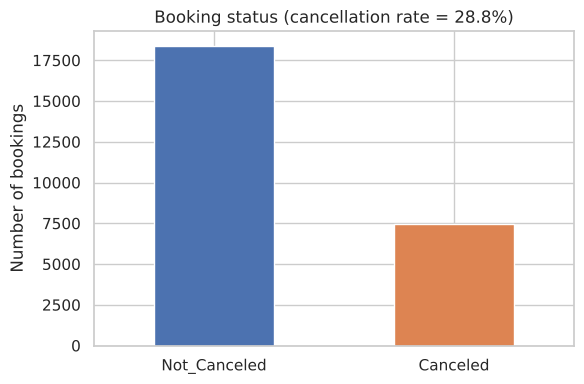

In [9]:
rate = df.is_canceled.mean()
ax = df.booking_status.value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(6, 4))
ax.set_title(f"Booking status (cancellation rate = {rate:.1%})"); ax.set_ylabel("Number of bookings"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

About **29% of bookings are cancelled**. The classes are imbalanced, so we will look at precision, recall and F1, not just accuracy, and use `class_weight='balanced'` in the models.

### 4.2 Lead time vs cancellation

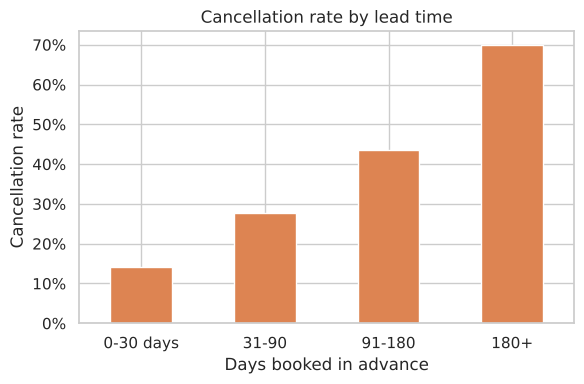

lead_time_group
0-30 days    0.140994
31-90        0.276533
91-180       0.436451
180+         0.699517
Name: is_canceled, dtype: float64

In [10]:
df["lead_time_group"] = pd.cut(df.lead_time, [-1, 30, 90, 180, 500], labels=["0-30 days", "31-90", "91-180", "180+"])
lt = df.groupby("lead_time_group", observed=True).is_canceled.mean()
ax = lt.plot(kind="bar", color="#DD8452", figsize=(6, 4))
ax.set_title("Cancellation rate by lead time"); ax.set_ylabel("Cancellation rate"); ax.set_xlabel("Days booked in advance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
lt

**Insight:** The earlier a booking is made, the more likely it is to be cancelled. Bookings made 180+ days ahead are cancelled far more often than those made within a month.

### 4.3 Special requests vs cancellation

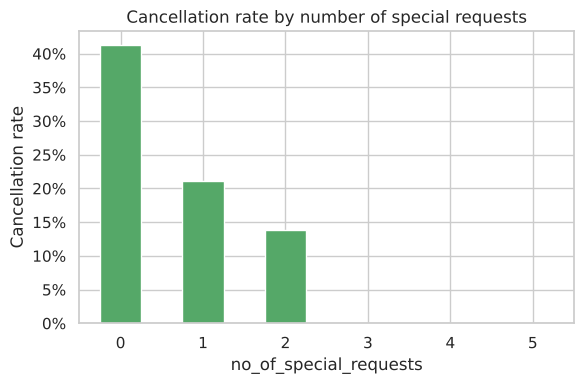

no_of_special_requests
0    0.412943
1    0.211326
2    0.138606
3    0.000000
4    0.000000
5    0.000000
Name: is_canceled, dtype: float64

In [11]:
sr = df.groupby("no_of_special_requests").is_canceled.mean()
ax = sr.plot(kind="bar", color="#55A868", figsize=(6, 4))
ax.set_title("Cancellation rate by number of special requests"); ax.set_ylabel("Cancellation rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
sr

**Insight:** Guests who make special requests are **committed** to the stay. With 3 or more requests, almost no one cancels.

### 4.4 Market segment vs cancellation

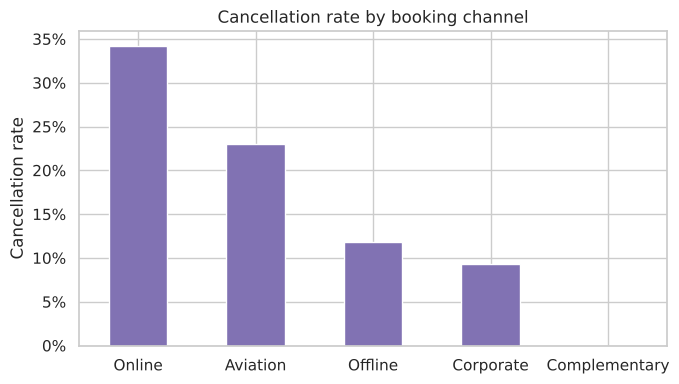

,mean,count
market_segment_type,,
Online,0.341965,19850
Aviation,0.230000,100
Offline,0.118450,4103
Corporate,0.092527,1405
Complementary,0.000000,345


In [12]:
ms = df.groupby("market_segment_type").is_canceled.agg(["mean", "count"]).sort_values("mean", ascending=False)
ax = ms["mean"].plot(kind="bar", color="#8172B3", figsize=(7, 4))
ax.set_title("Cancellation rate by booking channel"); ax.set_ylabel("Cancellation rate"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
ms

**Insight:** Online bookings cancel the most (easy to book, easy to cancel). Corporate and Complementary bookings rarely cancel.

### 4.5 Room price vs cancellation

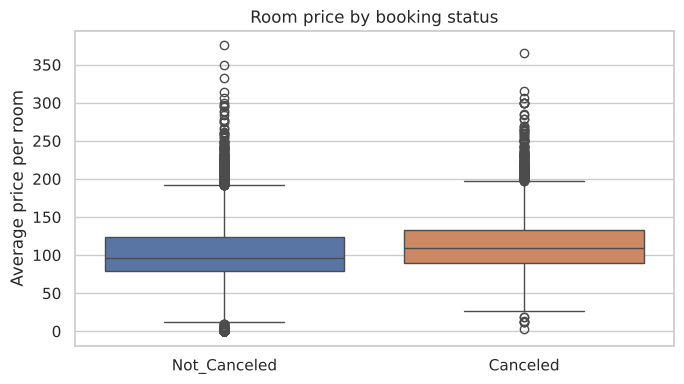

booking_status
Canceled        109.66
Not_Canceled     96.30
Name: avg_price_per_room, dtype: float64

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="booking_status", y="avg_price_per_room", hue="booking_status", palette=["#4C72B0", "#DD8452"], legend=False)
plt.title("Room price by booking status"); plt.xlabel(""); plt.ylabel("Average price per room")
plt.tight_layout(); plt.show()
df.groupby("booking_status").avg_price_per_room.median()

**Insight:** Cancelled bookings tend to have slightly **higher prices**, so guests may cancel expensive bookings when they find a cheaper option.

### 4.6 Repeat guests vs cancellation

In [14]:
df.groupby("repeated_guest").is_canceled.mean().rename({0: "New guest", 1: "Repeat guest"})

repeated_guest
New guest       0.297224
Repeat guest    0.009501
Name: is_canceled, dtype: float64

**Insight:** Repeat guests almost never cancel. Loyalty matters.

### 4.7 Cancellation rate by arrival month

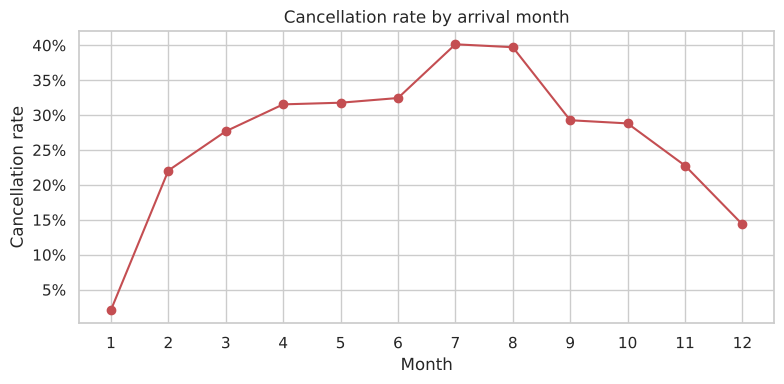

In [15]:
m = df.groupby("arrival_month").is_canceled.mean()
ax = m.plot(marker="o", color="#C44E52", figsize=(8, 4))
ax.set_title("Cancellation rate by arrival month"); ax.set_xlabel("Month"); ax.set_ylabel("Cancellation rate")
ax.set_xticks(range(1, 13)); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

**Insight:** Cancellations peak for **July and August** arrivals (about 40%) and are lowest in **January** and December. The hotel should use stricter deposit rules and plan overbooking for the summer peak.

### 4.8 Correlation between numeric features

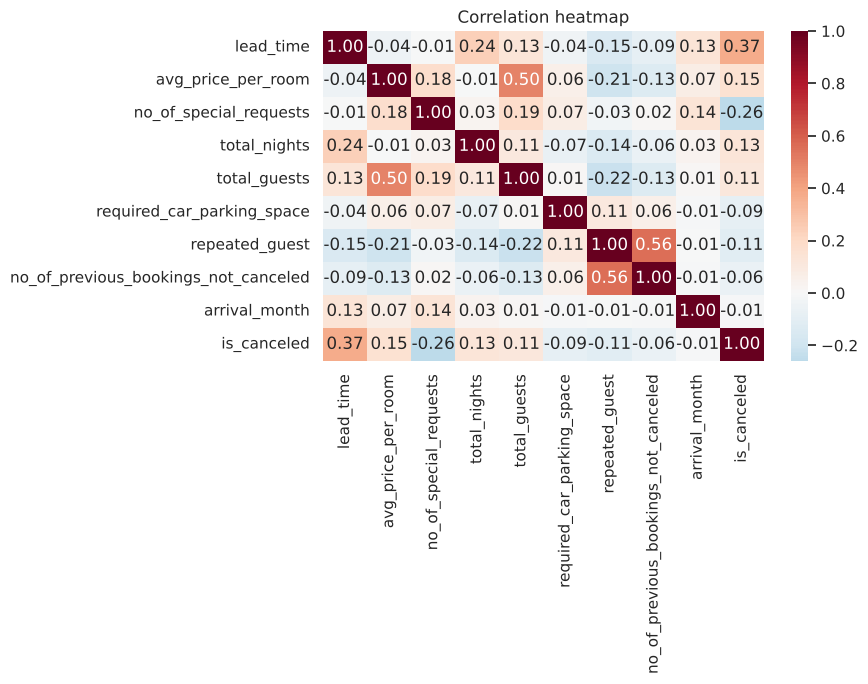

In [16]:
num_cols = ["lead_time", "avg_price_per_room", "no_of_special_requests", "total_nights", "total_guests",
            "required_car_parking_space", "repeated_guest", "no_of_previous_bookings_not_canceled", "arrival_month", "is_canceled"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

**Insight:** `lead_time` has the strongest positive link with cancellation; `no_of_special_requests` has the strongest negative link.

## 5. Prepare data for the model
- **Target (y):** `is_canceled` (1 = Canceled, 0 = Not Canceled)
- **Features (X):** booking details that are known **at the time of booking**. We leave out `arrival_year` (only 2017–2018, not useful for future bookings) and `arrival_date` (day of month adds little).
- **Numbers** are scaled with `StandardScaler`; **text columns** are converted to 0/1 columns with `OneHotEncoder`.
- Data is split **80% training / 20% testing**, keeping the same cancellation ratio in both (`stratify`).

In [17]:
numeric_features = ["no_of_adults", "no_of_children", "no_of_weekend_nights", "no_of_week_nights",
                    "required_car_parking_space", "lead_time", "arrival_month", "repeated_guest",
                    "no_of_previous_cancellations", "no_of_previous_bookings_not_canceled",
                    "avg_price_per_room", "no_of_special_requests"]
categorical_features = ["type_of_meal_plan", "room_type_reserved", "market_segment_type"]

X = df[numeric_features + categorical_features]
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training rows:", len(X_train), " Testing rows:", len(X_test))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

Training rows: 20642  Testing rows: 5161


## 6. Build and compare models
We try three models, from simple to more powerful:
1. **Logistic Regression**: simple and easy to explain (baseline)
2. **Decision Tree**: learns if-then rules
3. **Random Forest**: many decision trees voting together, usually more accurate and stable

In [18]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=2,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}

results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1 Score": f1_score(y_test, pred),
                    "ROC-AUC": roc_auc_score(y_test, prob)})

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.775,0.583,0.769,0.663,0.858
Decision Tree,0.828,0.681,0.757,0.717,0.885
Random Forest,0.849,0.723,0.772,0.747,0.913


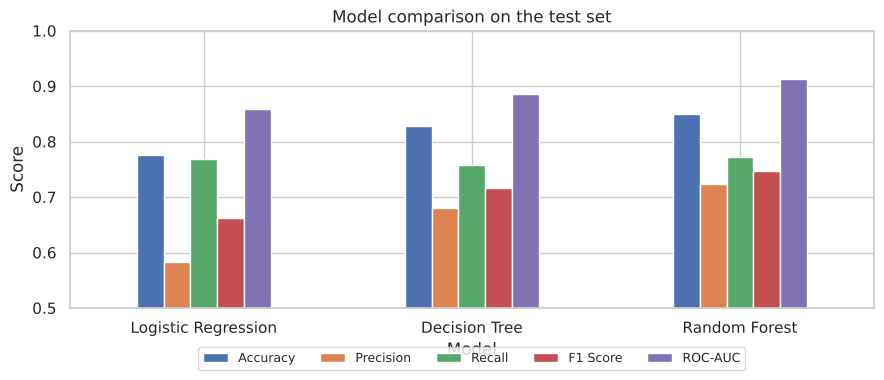

In [19]:
results_df.plot(kind="bar", figsize=(9, 4), ylim=(0.5, 1))
plt.title("Model comparison on the test set"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=9); plt.tight_layout(); plt.show()

**What the metrics mean**
- **Accuracy:** % of all bookings predicted correctly.
- **Precision:** of the bookings we *flagged* as "will cancel", how many really cancelled.
- **Recall:** of the bookings that *really* cancelled, how many we caught.
- **F1 Score:** balance of precision and recall (our main metric because classes are imbalanced).
- **ROC-AUC:** how well the model separates cancellers from non-cancellers (1.0 = perfect, 0.5 = guessing).

**Random Forest gives the best F1 and ROC-AUC, so we select it as the final model.**

## 7. Evaluate the final model (Random Forest)

In [20]:
best_name = results_df["F1 Score"].idxmax()
best = fitted[best_name]
print("Selected model:", best_name)
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Not Canceled", "Canceled"]))

Selected model: Random Forest
              precision    recall  f1-score   support

Not Canceled       0.91      0.88      0.89      3675
    Canceled       0.72      0.77      0.75      1486

    accuracy                           0.85      5161
   macro avg       0.81      0.83      0.82      5161
weighted avg       0.85      0.85      0.85      5161



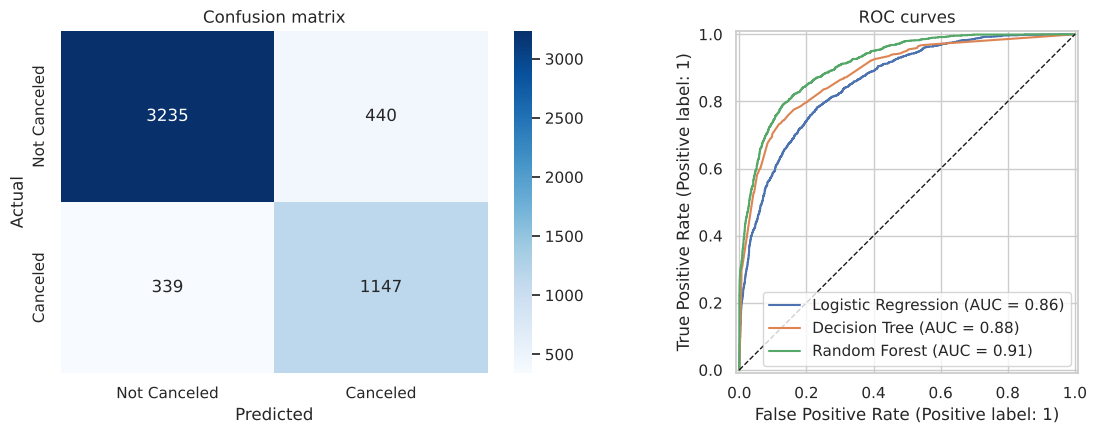

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Not Canceled", "Canceled"], yticklabels=["Not Canceled", "Canceled"])
axes[0].set_title("Confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("ROC curves")
plt.tight_layout(); plt.show()

**Reading the confusion matrix**
- Top-left: correctly predicted *Not Canceled*
- Bottom-right: correctly predicted *Canceled* (cancellations we caught in time)
- Bottom-left: cancellations we **missed** (most costly for the hotel: empty room)
- Top-right: false alarms (guest was flagged but did not cancel; low cost if the action is just a reminder)

## 8. Which factors matter most? (Feature importance)

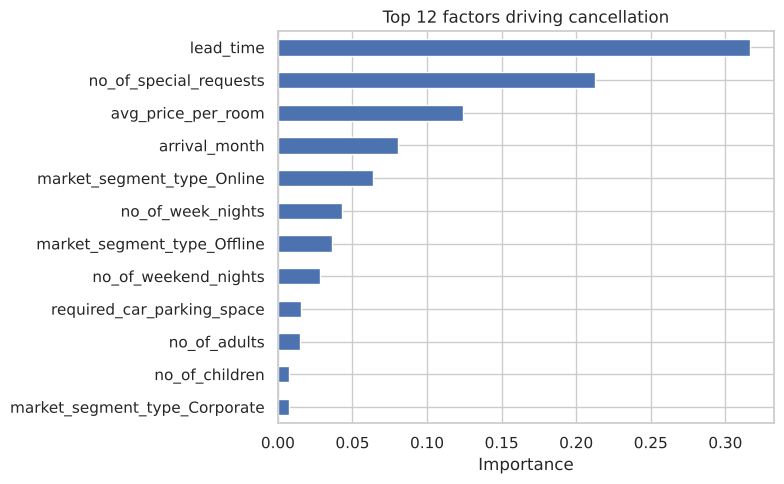

lead_time                        0.317
no_of_special_requests           0.212
avg_price_per_room               0.124
arrival_month                    0.080
market_segment_type_Online       0.064
no_of_week_nights                0.043
market_segment_type_Offline      0.036
no_of_weekend_nights             0.029
required_car_parking_space       0.015
no_of_adults                     0.015
no_of_children                   0.007
market_segment_type_Corporate    0.007
dtype: float64

In [22]:
feature_names = best.named_steps["preprocess"].get_feature_names_out()
feature_names = [f.split("__", 1)[1] for f in feature_names]
importances = pd.Series(best.named_steps["model"].feature_importances_, index=feature_names).sort_values(ascending=False)
ax = importances.head(12).sort_values().plot(kind="barh", color="#4C72B0", figsize=(8, 5))
ax.set_title("Top 12 factors driving cancellation"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()
importances.head(12).round(3)

**Insight:** Lead time, special requests, room price, arrival month and online booking (in that order) are the strongest drivers of cancellation.

## 9. Save the trained model

In [23]:
joblib.dump(best, "hotel_cancellation_model.pkl", compress=3)

metrics = results_df.loc[best_name].to_dict()
metrics["model"] = best_name
metrics["train_rows"] = len(X_train); metrics["test_rows"] = len(X_test)
metrics["cancellation_rate"] = round(float(y.mean()), 3)
with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("Saved hotel_cancellation_model.pkl and model_metrics.json")
metrics

Saved hotel_cancellation_model.pkl and model_metrics.json


{'Accuracy': 0.849,
 'Precision': 0.723,
 'Recall': 0.772,
 'F1 Score': 0.747,
 'ROC-AUC': 0.913,
 'model': 'Random Forest',
 'train_rows': 20642,
 'test_rows': 5161,
 'cancellation_rate': 0.288}

## 10. Test a prediction (same as the Streamlit app does)

In [24]:
model = joblib.load("hotel_cancellation_model.pkl")
sample = pd.DataFrame([{
    "no_of_adults": 2, "no_of_children": 0, "no_of_weekend_nights": 1, "no_of_week_nights": 2,
    "required_car_parking_space": 0, "lead_time": 200, "arrival_month": 8, "repeated_guest": 0,
    "no_of_previous_cancellations": 0, "no_of_previous_bookings_not_canceled": 0,
    "avg_price_per_room": 130.0, "no_of_special_requests": 0,
    "type_of_meal_plan": "Meal Plan 1", "room_type_reserved": "Room_Type 1", "market_segment_type": "Online"}])
p = model.predict_proba(sample)[0, 1]
print(f"Probability of cancellation: {p:.0%}")

Probability of cancellation: 97%


In [25]:
def recommend(p):
    if p >= 0.70:
        return "HIGH RISK: ask for a non-refundable deposit or prepayment, send reminder emails, and consider controlled overbooking for these dates."
    elif p >= 0.40:
        return "MEDIUM RISK: send a confirmation reminder 7 days before arrival and offer a small perk (free breakfast or upgrade) to encourage the guest to keep the booking."
    return "LOW RISK: confirm normally. Focus on a good guest experience and upselling."
print(recommend(p))

HIGH RISK: ask for a non-refundable deposit or prepayment, send reminder emails, and consider controlled overbooking for these dates.


## 11. Business insights and recommendations
1. **Long lead times are risky.** Bookings made months in advance cancel much more often. → Use stricter cancellation policies or partial prepayment for early bookings.
2. **Special requests signal commitment.** Guests with requests rarely cancel. → Encourage requests during booking (room view, airport pickup) to increase commitment.
3. **Online bookings cancel the most.** → Offer slightly cheaper *non-refundable* online rates; send automated reminders.
4. **Repeat guests are loyal.** → Invest in a loyalty programme; returning guests are low risk.
5. **Higher prices go with more cancellations.** → Guests may be shopping around; use price-match or value-add offers.
6. **Use the model daily.** Score every new booking; send high-risk bookings to the revenue team for action and use the predicted cancellations to plan **safe overbooking**.

## 12. Conclusion
We cleaned the data (removed duplicates, invalid dates and suspicious values), explored the main drivers of cancellation, and compared three models.
**Random Forest** performed best and was saved as `hotel_cancellation_model.pkl`. It is used in the Streamlit app (`app.py`), where a hotel manager enters booking details and gets the cancellation risk with a recommended action.

**Limitations:** data comes from one hotel group for 2017–2018; customer reasons for cancelling are not recorded; the model should be retrained regularly with new data.